# Figures: characteristic modes of a rectangular plate

Generates, for the page *Theory → Characteristic modes*:

- `cma_plate_sweep.svg`: tracked eigenvalues, modal significance and the spectrum of $R = \mathrm{Re}\,Z$;
- `cma_plate_currents.svg`: the characteristic currents of the first three modes at the first resonance.

The plate is the one of `solver/antenna_simulation/cma_implementation/plate_cma.ipynb` (100 mm × 50 mm, 7 mm cells). Everything goes through the solver's own functions (`rwg3.calculate_z_matrice_sweep`, `cma.eigen_solver`, `cma.mode_tracking`, `cma.mode_diagnostics`, `rwg5.calculate_current_density`), with the default `CMAParameters`, in memory: nothing is written to `data/`. A provenance file (`cma_plate.json`) records the solver commit and the numbers quoted on the page.

In [1]:
%matplotlib inline
import datetime
import json
import tempfile
import warnings
from pathlib import Path

import gmsh
import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager
from matplotlib.collections import PolyCollection

from solver.rwg.rwg1 import Points, Triangles, filter_complexes_jonctions
from solver.rwg.rwg2 import Vecteurs_Rho
from solver.rwg.rwg3 import calculate_z_matrice, calculate_z_matrice_sweep
from solver.rwg.rwg5 import calculate_current_density
from solver.cma.cma_parameters import CMAParameters
from solver.cma.eigen_solver import GeneralizedEigenSolver
from solver.cma.mode_tracking import track_sweep
from solver.cma.mode_diagnostics import mode_report
from solver.cma.modal_significance import modal_significance
from solver.cma.characteristic_angle import characteristic_angle

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)

BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
MODE_COLOURS = [BLUE, AMBER, INK, "#3a9a7a", "#8a5cc2", GREY]
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

# Defaults of CMAParameters (solver='regularized', sort_by='magnitude'), except n_modes.
# Tracking can only follow a mode while it stays among the n_modes kept at each frequency,
# so the window is wider (12) than the number of modes plotted (4).
PARAMS = CMAParameters(n_modes=12)
N_SHOW = 4
print(PARAMS)

CMAParameters(n_modes=12, regularization_epsilon=1e-10, normalize=True, sort_by='magnitude', solver='regularized', rank_tol=1e-06)


In [2]:
# The plate of plate_cma.ipynb, meshed by gmsh in memory, single-threaded.
LX, LY, H = 0.100, 0.050, 0.007

gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
gmsh.option.setNumber("General.NumThreads", 1)
gmsh.model.add("plate")
gmsh.model.occ.addRectangle(0, 0, 0, LX, LY)
gmsh.model.occ.synchronize()
gmsh.option.setNumber("Mesh.MeshSizeMin", H)
gmsh.option.setNumber("Mesh.MeshSizeMax", H)
gmsh.model.mesh.generate(2)
node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
p = np.asarray(node_coords).reshape(-1, 3).T
index_of = {int(tag): i for i, tag in enumerate(node_tags)}
blocks = []
for dim, surface in gmsh.model.getEntities(2):
    types, _, nodes = gmsh.model.mesh.getElements(dim, surface)
    for etype, enodes in zip(types, nodes):
        if etype == 2:
            idx = np.array([index_of[int(k)] for k in enodes]).reshape(-1, 3).T
            blocks.append(np.vstack([idx, np.full((1, idx.shape[1]), surface)]))
gmsh.finalize()
t = np.hstack(blocks).astype(int)

points = Points(p)
triangles = Triangles(t)
triangles.calculate_triangles_area_and_center(points)
edges = triangles.get_edges()
filter_complexes_jonctions(points, triangles, edges)
edges.compute_edges_length(points)
rho = Vecteurs_Rho()
rho.calculate_vecteurs_rho(points, triangles, edges)
N = edges.total_number_of_edges
print(f"{triangles.total_of_triangles} triangles, N = {N} RWG functions")

284 triangles, N = 403 RWG functions


In [3]:
# Z(f) for the band, then X J = lambda R J at every frequency.
# The sweep is assembled in packets of frequencies: on a GPU the batched intermediates grow
# with the number of frequencies per call (see the docstring of impedance_matrix_z_sweep_gpu),
# and 61 at once does not fit in a 4 GB card.
FREQS = np.linspace(0.5e9, 3.5e9, 61)
Z_all = np.concatenate([calculate_z_matrice_sweep(points, triangles, edges, packet)[-1]
                        for packet in np.array_split(FREQS, 10)])

eigvals, eigvecs, n_warnings = [], [], 0
for Z in Z_all:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        lam, J, _ = GeneralizedEigenSolver.solve(Z.real, Z.imag, PARAMS)
    n_warnings += len(caught)
    eigvals.append(lam)
    eigvecs.append(J)
eigvals, eigvecs = np.array(eigvals), np.array(eigvecs)     # (n_f, K), (n_f, N, K)
print(f"{len(FREQS)} frequencies, {PARAMS.n_modes} modes each, {n_warnings} regularisation warnings")

# Cross-frequency tracking (R-weighted correlation + linear assignment)
tracking = track_sweep(FREQS, eigvals, eigvecs, R_list=Z_all.real)
lam_t = tracking.reorder(eigvals)
J_t = tracking.reorder_eigenvectors(eigvecs)
print(tracking.summary())

# Per-mode physical diagnostics at every frequency
verdicts = np.array([mode_report(J_t[i], Z_all[i].real, Z_all[i].imag, lam_t[i])["verdict"]
                     for i in range(len(FREQS))])                      # (n_f, K)
print("modes flagged SPURIOUS:", int(np.sum(verdicts == "SPURIOUS")), "of", verdicts.size)
spurious_shown = {f"mode {k + 1}": int(np.sum(verdicts[:, k] == "SPURIOUS")) for k in range(N_SHOW)}
print("among the plotted modes:", spurious_shown)
print("tracked modes flagged at least once:",
      [k + 1 for k in range(verdicts.shape[1]) if np.any(verdicts[:, k] == "SPURIOUS")])

[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 7 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


... (2 outputs left out)

[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


[calculate_z_matrice_sweep] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges, 6 frequencies).


61 frequencies, 12 modes each, 0 regularisation warnings
Mode tracking: 12 modes over 61 frequencies (metric='R', correction='none')
  accepted correlation: min 0.7594, median 0.9998
  assignment margin:    min 0.2014
  swap               18
  degeneracy         27


modes flagged SPURIOUS: 113 of 732
among the plotted modes: {'mode 1': 0, 'mode 2': 0, 'mode 3': 3, 'mode 4': 3}
tracked modes flagged at least once: [3, 4, 5, 6, 7, 9, 10, 11]


In [4]:
# Resonances: zero crossings of the tracked eigenvalue curves (linear interpolation)
resonances = []
for k in range(lam_t.shape[1]):
    s = np.sign(lam_t[:, k])
    for i in np.flatnonzero(s[:-1] * s[1:] < 0):
        f0 = FREQS[i] - lam_t[i, k] * (FREQS[i + 1] - FREQS[i]) / (lam_t[i + 1, k] - lam_t[i, k])
        resonances.append((float(f0), k))
resonances.sort()
for f0, k in resonances:
    print(f"tracked mode {k + 1}: lambda = 0 at {f0 / 1e9:.4f} GHz")

# Spectrum of R at the two ends of the band and at the first resonance
def r_spectrum(Z):
    mu_R = np.linalg.eigvalsh(0.5 * (Z.real + Z.real.T))[::-1]
    return mu_R / mu_R[0]
spectra = {f"{FREQS[i] / 1e9:.1f} GHz": r_spectrum(Z_all[i]) for i in (0, len(FREQS) // 2, len(FREQS) - 1)}
for name, s in spectra.items():
    print(f"{name}: rank of R at 1e-6 x max = {int(np.sum(s > 1e-6))} of {N}")

tracked mode 1: lambda = 0 at 1.3239 GHz
tracked mode 5: lambda = 0 at 3.0711 GHz
0.5 GHz: rank of R at 1e-6 x max = 12 of 403
2.0 GHz: rank of R at 1e-6 x max = 27 of 403
3.5 GHz: rank of R at 1e-6 x max = 44 of 403


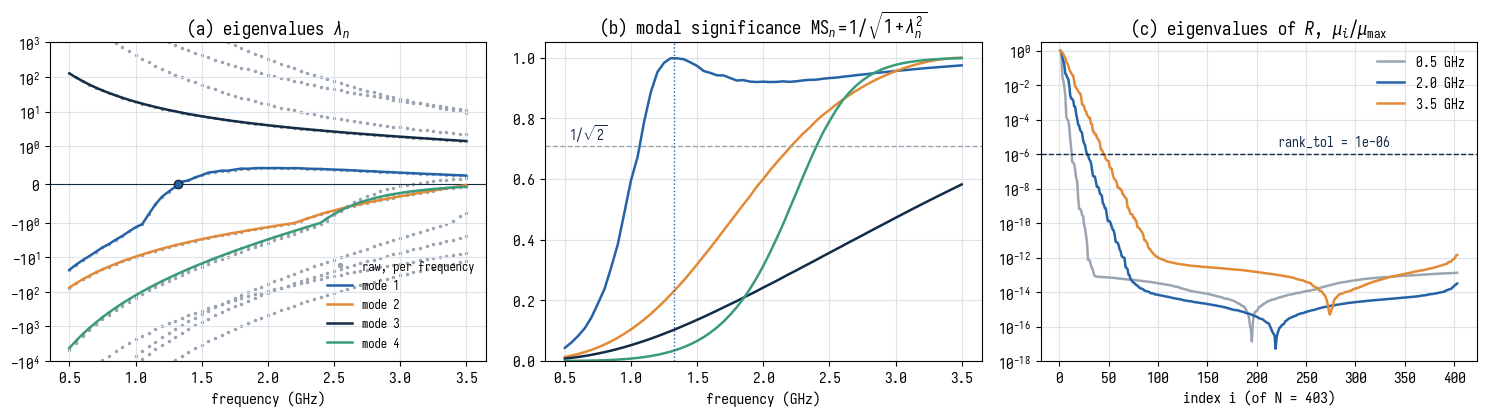

In [5]:
fig, (ax_l, ax_ms, ax_r) = plt.subplots(1, 3, figsize=(15, 4.3))
f_ghz = FREQS / 1e9

# Raw per-frequency values (sorted by |lambda| at each frequency, no identity) in grey
for k in range(eigvals.shape[1]):
    ax_l.plot(f_ghz, eigvals[:, k], ".", color=GREY, ms=3, zorder=1)
ax_l.plot([], [], ".", color=GREY, ms=6, label="raw, per frequency")

for k in range(N_SHOW):
    col = MODE_COLOURS[k]
    ax_l.plot(f_ghz, lam_t[:, k], color=col, lw=1.8, label=f"mode {k + 1}", zorder=3)
    ax_ms.plot(f_ghz, modal_significance(lam_t[:, k]), color=col, lw=1.8, label=f"mode {k + 1}")
for f0, k in resonances:
    if k < N_SHOW:
        ax_l.plot(f0 / 1e9, 0, "o", color=MODE_COLOURS[k], mec=INK, ms=6, zorder=5)
        ax_ms.axvline(f0 / 1e9, color=MODE_COLOURS[k], ls=":", lw=1)

ax_l.set_yscale("symlog", linthresh=1.0)
ax_l.axhline(0, color=INK, lw=0.8)
ax_l.set_ylim(-1e4, 1e3)
ax_l.set_title(r"(a) eigenvalues $\lambda_n$")
ax_l.set_xlabel("frequency (GHz)")
ax_l.legend(frameon=False, fontsize=9, loc="lower right")

ax_ms.axhline(1 / np.sqrt(2), color=GREY, ls="--", lw=1)
ax_ms.text(f_ghz[0] + 0.03, 1 / np.sqrt(2) + 0.02, r"$1/\sqrt{2}$", color=INK, fontsize=10)
ax_ms.set_ylim(0, 1.05)
ax_ms.set_title(r"(b) modal significance $\mathrm{MS}_n = 1/\sqrt{1+\lambda_n^2}$")
ax_ms.set_xlabel("frequency (GHz)")

for (name, s), col in zip(spectra.items(), (GREY, BLUE, AMBER)):
    ax_r.semilogy(np.arange(1, len(s) + 1), np.maximum(np.abs(s), 1e-18), color=col, lw=1.8, label=name)
ax_r.axhline(PARAMS.rank_tol, color=INK, ls="--", lw=1)
ax_r.text(len(s) * 0.55, PARAMS.rank_tol * 3, f"rank_tol = {PARAMS.rank_tol:g}", color=INK, fontsize=10)
ax_r.set_ylim(1e-18, 3)
ax_r.set_title(r"(c) eigenvalues of $R$, $\mu_i/\mu_{\max}$")
ax_r.set_xlabel(f"index i (of N = {N})")
ax_r.legend(frameon=False, fontsize=10, loc="upper right")
for ax in (ax_l, ax_ms, ax_r):
    ax.grid(True, color="#dde3ea", lw=0.8)

fig.tight_layout()
fig.savefig(OUT_DIR / "cma_plate_sweep.svg", bbox_inches="tight", facecolor="white")
plt.show()

[calculate_z_matrice] Using GPU (NVIDIA T600 Laptop GPU, CuPy 14.1.1) for the impedance matrix assembly (403x403 edges).


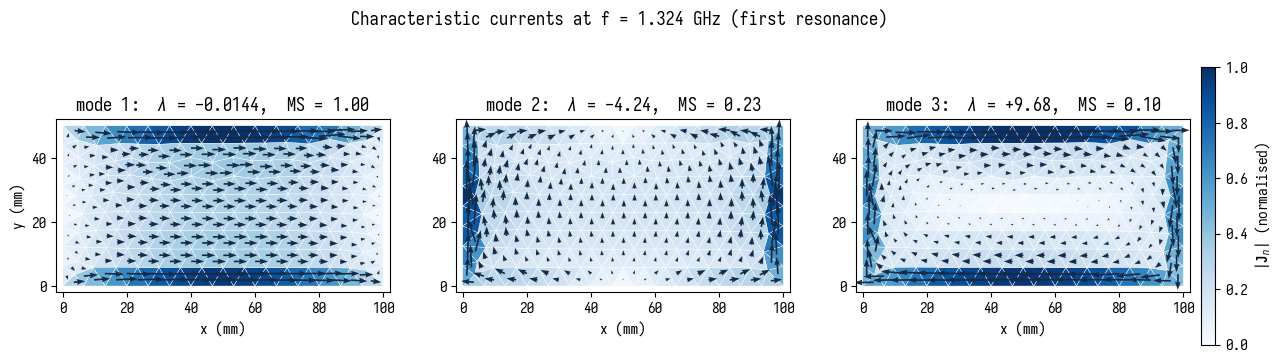

verdicts at resonance: [np.str_('PHYSICAL'), np.str_('PHYSICAL'), np.str_('PHYSICAL')]


In [6]:
# Characteristic currents at the first resonance, solved at that exact frequency
F_RES = resonances[0][0]
*_, Z_res = calculate_z_matrice(points, triangles, edges, F_RES)
lam_res, J_res, _ = GeneralizedEigenSolver.solve(Z_res.real, Z_res.imag, PARAMS)
report_res = mode_report(J_res, Z_res.real, Z_res.imag, lam_res)

mm = 1e3
P = points.points
polys = [P[:2, triangles.triangles[:3, tt]].T * mm for tt in range(triangles.total_of_triangles)]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for k, ax in enumerate(axes):
    J_abs, J_vec = calculate_current_density(J_res[:, k], triangles, edges, rho)
    J_vec = np.real(J_vec)
    pc = PolyCollection(polys, array=J_abs / J_abs.max(), cmap="Blues", edgecolors="white", linewidths=0.3)
    pc.set_clim(0, 1)
    ax.add_collection(pc)
    c_t = triangles.triangles_center[:2] * mm
    scale = np.linalg.norm(J_vec[:2], axis=0).max()
    ax.quiver(c_t[0], c_t[1], J_vec[0] / scale, J_vec[1] / scale, color=INK, angles="xy",
              scale_units="xy", scale=1 / (1.6 * H * mm), width=0.005, headwidth=3.5, minlength=0)
    ax.set_xlim(-2, LX * mm + 2)
    ax.set_ylim(-2, LY * mm + 2)
    ax.set_aspect("equal")
    ax.set_title(f"mode {k + 1}:  " + r"$\lambda$" + f" = {lam_res[k]:+.3g},  MS = {modal_significance(lam_res[k]):.2f}")
    ax.set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
fig.colorbar(pc, ax=axes, fraction=0.015, pad=0.01, label=r"$|\mathbf{J}_n|$ (normalised)")
fig.suptitle(f"Characteristic currents at f = {F_RES / 1e9:.3f} GHz (first resonance)", y=1.04)
fig.savefig(OUT_DIR / "cma_plate_currents.svg", bbox_inches="tight", facecolor="white")
plt.show()
print("verdicts at resonance:", list(report_res["verdict"][:3]))

In [7]:
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

provenance = {
    "figures": ["cma_plate_sweep.svg", "cma_plate_currents.svg"],
    "notebook": "documentation/figure_notebooks/theory_characteristic_modes.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "cma_parameters": {k: getattr(PARAMS, k) for k in ("n_modes", "solver", "sort_by", "regularization_epsilon", "rank_tol")},
    "mesh": {"plate_m": [LX, LY], "element_size_m": H, "triangles": int(triangles.total_of_triangles), "rwg_functions": int(N)},
    "sweep_hz": [float(FREQS[0]), float(FREQS[-1]), len(FREQS)],
    "regularisation_warnings": n_warnings,
    "tracking_summary": tracking.summary(),
    "spurious_in_sweep": int(np.sum(verdicts == "SPURIOUS")),
    "spurious_among_plotted_modes": spurious_shown,
    "resonances_ghz": [{"tracked_mode": k + 1, "f_ghz": round(f0 / 1e9, 4)} for f0, k in resonances],
    "rank_R_at_1e-6": {name: int(np.sum(s > 1e-6)) for name, s in spectra.items()},
    "at_first_resonance": {"f_ghz": round(F_RES / 1e9, 4),
                           "lambda": [round(float(x), 5) for x in lam_res[:3]],
                           "verdict": [str(v) for v in report_res["verdict"][:3]]},
}
(OUT_DIR / "cma_plate.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps(provenance, indent=2))

{
  "figures": [
    "cma_plate_sweep.svg",
    "cma_plate_currents.svg"
  ],
  "notebook": "documentation/figure_notebooks/theory_characteristic_modes.ipynb",
  "solver_commit": "2106e70",
  "generated": "2026-11-11",
  "cma_parameters": {
    "n_modes": 12,
    "solver": "regularized",
    "sort_by": "magnitude",
    "regularization_epsilon": 1e-10,
    "rank_tol": 1e-06
  },
  "mesh": {
    "plate_m": [
      0.1,
      0.05
    ],
    "element_size_m": 0.007,
    "triangles": 284,
    "rwg_functions": 403
  },
  "sweep_hz": [
    500000000.0,
    3500000000.0,
    61
  ],
  "regularisation_warnings": 0,
  "tracking_summary": "Mode tracking: 12 modes over 61 frequencies (metric='R', correction='none')\n  accepted correlation: min 0.7594, median 0.9998\n  assignment margin:    min 0.2014\n  swap               18\n  degeneracy         27",
  "spurious_in_sweep": 113,
  "spurious_among_plotted_modes": {
    "mode 1": 0,
    "mode 2": 0,
    "mode 3": 3,
    "mode 4": 3
  },
  "resonanc